In [1]:
import gurobipy as gp
from gurobipy import GRB


import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

# Input

In [2]:
import json

with open("data/toy_instance.json") as f:
    inst = json.load(f)

# Sets
h = inst["horizon"]
H = range(1, h + 1)                              # time horizon {1, ..., h}
Q = inst["qualifications"]                       # qualifications
S = [s["name"] for s in inst["staff"]]           # staff
J = [j["name"] for j in inst["jobs"]]            # projects

# Staff parameters
Q_i = {s["name"]: set(s["qualifications"]) for s in inst["staff"]}   # Q_i ⊆ Q
V_i = {s["name"]: set(s["vacations"]) for s in inst["staff"]}        # V_i ⊆ H

# Project parameters
Q_j = {j["name"]: set(j["working_days_per_qualification"]) for j in inst["jobs"]}   # Q_j' ⊆ Q
n = {(j["name"], k): days
     for j in inst["jobs"]
     for k, days in j["working_days_per_qualification"].items()}     # n[j, k]
g = {j["name"]: j["gain"] for j in inst["jobs"]}                     # gain g_j
d = {j["name"]: j["due_date"] for j in inst["jobs"]}                 # due date d_j
c = {j["name"]: j["daily_penalty"] for j in inst["jobs"]}            # penalty c_j'

In [3]:
n

{('Job1', 'A'): 1,
 ('Job1', 'B'): 1,
 ('Job1', 'C'): 1,
 ('Job2', 'A'): 1,
 ('Job2', 'B'): 2,
 ('Job3', 'A'): 1,
 ('Job3', 'C'): 2,
 ('Job4', 'B'): 2,
 ('Job4', 'C'): 1,
 ('Job5', 'C'): 2}

In [4]:
V_i

{'Olivia': set(), 'Liam': {1}, 'Emma': {2}}

In [5]:
Q_j

{'Job1': {'A', 'B', 'C'},
 'Job2': {'A', 'B'},
 'Job3': {'A', 'C'},
 'Job4': {'B', 'C'},
 'Job5': {'C'}}

In [6]:
for k in Q_j["Job1"]:
    print(k)

A
C
B


In [7]:
for i in n:
    print(i)

('Job1', 'A')
('Job1', 'B')
('Job1', 'C')
('Job2', 'A')
('Job2', 'B')
('Job3', 'A')
('Job3', 'C')
('Job4', 'B')
('Job4', 'C')
('Job5', 'C')


In [8]:
g

{'Job1': 20, 'Job2': 15, 'Job3': 15, 'Job4': 20, 'Job5': 10}

In [9]:
d

{'Job1': 3, 'Job2': 3, 'Job3': 4, 'Job4': 3, 'Job5': 5}

In [10]:
c

{'Job1': 3, 'Job2': 3, 'Job3': 3, 'Job4': 3, 'Job5': 3}

# Model

In [11]:
# Create initial model.
m = gp.Model("staff")

Set parameter Username
Set parameter LicenseID to value 2885186
Academic license - for non-commercial use only - expires 2027-11-16


# Variables

In [ ]:
# Initialize assignment decision variables.

# x[i,t,j,k]: only valid combinations (satff i, t working day, job skills needed for project k)
idx = [(i, t, j, k)
       for i in S
       for t in H if t not in V_i[i]
       for j in J
       for k in Q_j[j] & Q_i[i]]

idx

[('Olivia', 1, 'Job1', 'A'),
 ('Olivia', 1, 'Job1', 'C'),
 ('Olivia', 1, 'Job1', 'B'),
 ('Olivia', 1, 'Job2', 'A'),
 ('Olivia', 1, 'Job2', 'B'),
 ('Olivia', 1, 'Job3', 'A'),
 ('Olivia', 1, 'Job3', 'C'),
 ('Olivia', 1, 'Job4', 'C'),
 ('Olivia', 1, 'Job4', 'B'),
 ('Olivia', 1, 'Job5', 'C'),
 ('Olivia', 2, 'Job1', 'A'),
 ('Olivia', 2, 'Job1', 'C'),
 ('Olivia', 2, 'Job1', 'B'),
 ('Olivia', 2, 'Job2', 'A'),
 ('Olivia', 2, 'Job2', 'B'),
 ('Olivia', 2, 'Job3', 'A'),
 ('Olivia', 2, 'Job3', 'C'),
 ('Olivia', 2, 'Job4', 'C'),
 ('Olivia', 2, 'Job4', 'B'),
 ('Olivia', 2, 'Job5', 'C'),
 ('Olivia', 3, 'Job1', 'A'),
 ('Olivia', 3, 'Job1', 'C'),
 ('Olivia', 3, 'Job1', 'B'),
 ('Olivia', 3, 'Job2', 'A'),
 ('Olivia', 3, 'Job2', 'B'),
 ('Olivia', 3, 'Job3', 'A'),
 ('Olivia', 3, 'Job3', 'C'),
 ('Olivia', 3, 'Job4', 'C'),
 ('Olivia', 3, 'Job4', 'B'),
 ('Olivia', 3, 'Job5', 'C'),
 ('Olivia', 4, 'Job1', 'A'),
 ('Olivia', 4, 'Job1', 'C'),
 ('Olivia', 4, 'Job1', 'B'),
 ('Olivia', 4, 'Job2', 'A'),
 ('Olivia', 4,

In [ ]:
# matrix of people, job, skill, day
x = m.addVars(idx, vtype=GRB.BINARY, name="x")

# auxilliary variable: project j completed in horizon
y = m.addVars(J, vtype=GRB.BINARY, name='y')

# completion day of the project
e = m.addVars(J, vtype=GRB.INTEGER, lb=0, ub=h, name='e')

# number of days late of the project
l = m.addVars(J, vtype=GRB.INTEGER, lb=0, name='l')

In [ ]:
# auxiliary variables (used to express the objectives)

# last_day: last completion day over all projects (makespan)
last_day = m.addVar(vtype=GRB.INTEGER, lb=0, ub=h, name="last_day")

# z[i,j] = 1 if employee i works at least one day on project j
z = m.addVars(S, J, vtype=GRB.BINARY, name="project_worked")

# P: max number of projects worked on by any single employee
P = m.addVar(vtype=GRB.INTEGER, lb=0, ub=len(J), name="max_projects")

# r[j] = 1 if project j is delivered late, 0 otherwise
r = m.addVars(J, vtype=GRB.BINARY, name="late")

# Constraints

In [ ]:
# one staff member works on at most one project per day
daily_assignment = m.addConstrs(
    (x.sum(i, t, "*", "*") <= 1 for i in S for t in H if t not in V_i[i]),
    name="daily_assignment",
)
daily_assignment

{('Olivia', 1): <gurobi.Constr *Awaiting Model Update*>,
 ('Olivia', 2): <gurobi.Constr *Awaiting Model Update*>,
 ('Olivia', 3): <gurobi.Constr *Awaiting Model Update*>,
 ('Olivia', 4): <gurobi.Constr *Awaiting Model Update*>,
 ('Olivia', 5): <gurobi.Constr *Awaiting Model Update*>,
 ('Liam', 2): <gurobi.Constr *Awaiting Model Update*>,
 ('Liam', 3): <gurobi.Constr *Awaiting Model Update*>,
 ('Liam', 4): <gurobi.Constr *Awaiting Model Update*>,
 ('Liam', 5): <gurobi.Constr *Awaiting Model Update*>,
 ('Emma', 1): <gurobi.Constr *Awaiting Model Update*>,
 ('Emma', 3): <gurobi.Constr *Awaiting Model Update*>,
 ('Emma', 4): <gurobi.Constr *Awaiting Model Update*>,
 ('Emma', 5): <gurobi.Constr *Awaiting Model Update*>}

In [16]:
# a project is either fully covered for each qualification (y=1) or not worked on at all (y=0)
completed_project = m.addConstrs((x.sum("*", "*", j, k) == n[j,k] * y[j] for j in J for k in Q_j[j]), name="coverage",)
completed_project

{('Job1', 'A'): <gurobi.Constr *Awaiting Model Update*>,
 ('Job1', 'C'): <gurobi.Constr *Awaiting Model Update*>,
 ('Job1', 'B'): <gurobi.Constr *Awaiting Model Update*>,
 ('Job2', 'A'): <gurobi.Constr *Awaiting Model Update*>,
 ('Job2', 'B'): <gurobi.Constr *Awaiting Model Update*>,
 ('Job3', 'A'): <gurobi.Constr *Awaiting Model Update*>,
 ('Job3', 'C'): <gurobi.Constr *Awaiting Model Update*>,
 ('Job4', 'C'): <gurobi.Constr *Awaiting Model Update*>,
 ('Job4', 'B'): <gurobi.Constr *Awaiting Model Update*>,
 ('Job5', 'C'): <gurobi.Constr *Awaiting Model Update*>}

In [17]:
# the completion day is at least every day someone works on the project
end_day = m.addConstrs((e[j] >= t * x[i, t, j, k] for (i, t, j, k) in idx), name="end_day")
end_day

{('Olivia', 1, 'Job1', 'A'): <gurobi.Constr *Awaiting Model Update*>,
 ('Olivia', 1, 'Job1', 'C'): <gurobi.Constr *Awaiting Model Update*>,
 ('Olivia', 1, 'Job1', 'B'): <gurobi.Constr *Awaiting Model Update*>,
 ('Olivia', 1, 'Job2', 'A'): <gurobi.Constr *Awaiting Model Update*>,
 ('Olivia', 1, 'Job2', 'B'): <gurobi.Constr *Awaiting Model Update*>,
 ('Olivia', 1, 'Job3', 'A'): <gurobi.Constr *Awaiting Model Update*>,
 ('Olivia', 1, 'Job3', 'C'): <gurobi.Constr *Awaiting Model Update*>,
 ('Olivia', 1, 'Job4', 'C'): <gurobi.Constr *Awaiting Model Update*>,
 ('Olivia', 1, 'Job4', 'B'): <gurobi.Constr *Awaiting Model Update*>,
 ('Olivia', 1, 'Job5', 'C'): <gurobi.Constr *Awaiting Model Update*>,
 ('Olivia', 2, 'Job1', 'A'): <gurobi.Constr *Awaiting Model Update*>,
 ('Olivia', 2, 'Job1', 'C'): <gurobi.Constr *Awaiting Model Update*>,
 ('Olivia', 2, 'Job1', 'B'): <gurobi.Constr *Awaiting Model Update*>,
 ('Olivia', 2, 'Job2', 'A'): <gurobi.Constr *Awaiting Model Update*>,
 ('Olivia', 2, 'Job2

In [18]:
# days late = completion day - due date (0 if on time)
lateness = m.addConstrs((l[j] >= e[j] - d[j] for j in J), name="lateness")
lateness

{'Job1': <gurobi.Constr *Awaiting Model Update*>,
 'Job2': <gurobi.Constr *Awaiting Model Update*>,
 'Job3': <gurobi.Constr *Awaiting Model Update*>,
 'Job4': <gurobi.Constr *Awaiting Model Update*>,
 'Job5': <gurobi.Constr *Awaiting Model Update*>}

In [ ]:
# link the auxiliary variables to x, e and l

# last_day = max of the completion days
makespan = m.addConstr(last_day == gp.max_(list(e.values())), name="makespan")

# z[i,j] = OR of all x[i,t,j,k]: 1 as soon as employee i works one day on project j
project_worked = {
    (i, j): m.addGenConstrOr(
        z[i, j],
        [x[i, t, j, k] for t in H for k in Q if (i, t, j, k) in x],
        name=f"project_worked[{i},{j}]",
    )
    for i in S for j in J
}

# P is at least the number of projects of each employee
max_projects = m.addConstrs((P >= z.sum(i, "*") for i in S), name="max_projects")

# r[j] = 0 -> no delay ; r[j] = 1 -> at least one day late (l is integer)
late_off = m.addConstrs(((r[j] == 0) >> (l[j] == 0) for j in J), name="late_off")
late_on  = m.addConstrs(((r[j] == 1) >> (l[j] >= 1) for j in J), name="late_on")

# Objective functions

In [ ]:
# Objectives functions

# 1) Maximize total profit realized
def objective_profit(y, g, c, l):
    # gain of completed projects - late penalty * days late
    return gp.quicksum(g[j] * y[j] - c[j] * l[j] for j in J)

# 2) Minimize the actual project execution time
def objective_execution_time(last_day):
    # last completion day over all projects
    return last_day

# 3) Minimize the number of projects an employee works on
def objective_projects_per_employee(P):
    # max number of projects worked on by any employee
    return P

# 4) Minimize the number of projects delivered late
def objective_projects_late(r):
    # number of projects delivered late
    return r.sum()

In [21]:
# build the 4 objectives
profit = objective_profit(y, g, c, l)
execution_time = objective_execution_time(last_day)
projects_per_employee = objective_projects_per_employee(P)
projects_late = objective_projects_late(r)

In [ ]:
# hierarchical optimization: the higher the priority, the earlier the objective is optimized.

# ModelSense is MAXIMIZE, so the objectives to minimize get weight = -1
m.ModelSense = GRB.MAXIMIZE

m.setObjectiveN(profit,                index=0, priority=4, weight=1,  name="profit")
m.setObjectiveN(execution_time,        index=1, priority=3, weight=-1, name="execution_time")
m.setObjectiveN(projects_per_employee, index=2, priority=2, weight=-1, name="projects_per_employee")
m.setObjectiveN(projects_late,         index=3, priority=1, weight=-1, name="projects_late")

# Solve

In [23]:
m.optimize()

Gurobi Optimizer version 13.0.3 build v13.0.3rc0 (mac64[arm] - Darwin 27.2.0 26B131)

CPU model: Apple M5 Pro
Thread count: 18 physical cores, 18 logical processors, using up to 18 threads

Optimize a model with 121 rows, 127 columns and 398 nonzeros (Max)
Model fingerprint: 0x83e0d471
Model has 10 linear objective coefficients
Model has 26 simple general constraints
  1 MAX, 15 OR, 10 INDICATOR
Variable types: 0 continuous, 127 integer (115 binary)
Coefficient statistics:
  Matrix range     [1e+00, 5e+00]
  Objective range  [1e+00, 2e+01]
  Bounds range     [1e+00, 5e+00]
  RHS range        [1e+00, 5e+00]
  GenCon rhs range [1e+00, 1e+00]
  GenCon coe range [1e+00, 1e+00]


---------------------------------------------------------------------------
Multi-objectives: starting optimization (max) with 4 objectives... 
---------------------------------------------------------------------------

Multi-objectives: applying initial presolve...
------------------------------------------------

# Results

In [24]:
# value of each objective
for o in range(m.NumObj):
    m.Params.ObjNumber = o
    print(f"{m.ObjNName}: {m.ObjNVal:g}")

profit: 65
execution_time: 5
projects_per_employee: 2
projects_late: 0


In [25]:
# schedule: staff x days
schedule = pd.DataFrame("", index=S, columns=list(H))
for i in S:
    for t in V_i[i]:
        schedule.loc[i, t] = "vacation"
for (i, t, j, k), var in x.items():
    if var.X > 0.5:
        schedule.loc[i, t] = f"{j} ({k})"

schedule

,1,2,3,4,5
Olivia,Job4 (C),Job4 (B),Job4 (B),Job5 (C),Job5 (C)
Liam,vacation,Job1 (B),Job1 (A),Job3 (A),
Emma,Job3 (C),vacation,Job1 (C),Job3 (C),


In [26]:
# projects: completed or not, completion day and delay
projects = pd.DataFrame({
    "completed": {j: int(round(y[j].X)) for j in J},
    "end_day":   {j: int(round(e[j].X)) if y[j].X > 0.5 else None for j in J},
    "due_date":  d,
    "days_late": {j: int(round(l[j].X)) for j in J},
    "gain":      g,
})

projects

,completed,end_day,due_date,days_late,gain
Job1,1,3.0,3,0,20
Job2,0,NaN,3,0,15
Job3,1,4.0,4,0,15
Job4,1,3.0,3,0,20
Job5,1,5.0,5,0,10


In [27]:
# epsilon-constraint: maximize profit, then minimize execution time to break ties
m.setObjectiveN(profit,                0, priority=2, weight=1,  name="profit")
m.setObjectiveN(execution_time,        1, priority=1, weight=-1, name="execution_time")
m.setObjectiveN(projects_per_employee, 2, priority=0, weight=0)
m.setObjectiveN(projects_late,         3, priority=0, weight=0)
m.Params.OutputFlag = 0

eps_constr = m.addConstr(execution_time <= h, name="eps")
pareto = []
eps = h
while eps >= 0:
    eps_constr.RHS = eps
    m.optimize()
    if m.Status != GRB.OPTIMAL:
        break
    t = round(execution_time.X)
    pareto.append((profit.getValue(), t))
    eps = t - 1

m.remove(eps_constr)
m.Params.OutputFlag = 1
pareto


Set parameter OutputFlag to value 1


[(65.0, 5), (55.0, 4), (40.0, 3), (20.0, 2), (10.0, 1), (0.0, 0)]

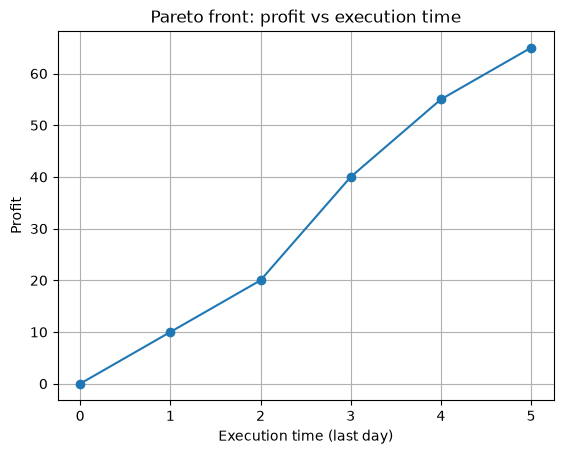

In [28]:
times   = [t for p, t in pareto]
profits = [p for p, t in pareto]

plt.plot(times, profits, "o-")
plt.xlabel("Execution time (last day)")
plt.ylabel("Profit")
plt.title("Pareto front: profit vs execution time")
plt.grid(True)
plt.show()


In [29]:
import os
import random
import time

objectives = {
    "profit": profit,
    "execution_time": execution_time,
    "projects_per_employee": projects_per_employee,
    "projects_late": projects_late,
}


# objective values computed from the schedule, not from the auxiliary variables
def get_solution(x, d, g, c):
    schedule = [key for key, var in x.items() if var.X > 0.5]

    end_day = {}
    projects_of = {}
    for (i, t, j, k) in schedule:
        end_day[j] = max(end_day.get(j, 0), t)
        projects_of.setdefault(i, set()).add(j)
    days_late = {j: max(0, end_day[j] - d[j]) for j in end_day}

    return {
        "profit": sum(g[j] - c[j] * days_late[j] for j in end_day),
        "execution_time": max(end_day.values(), default=0),
        "projects_per_employee": max([len(p) for p in projects_of.values()], default=0),
        "projects_late": sum(1 for j in days_late if days_late[j] > 0),
        "schedule": schedule,
    }


def solve_with_limits(m, x, objectives, limits, d, g, c):
    for index, name in enumerate(objectives):
        if name == "profit":
            m.setObjectiveN(objectives[name], index, priority=2, weight=1, name=name)
        elif name in limits:
            m.setObjectiveN(objectives[name], index, priority=1, weight=-1, name=name)
        else:
            m.setObjectiveN(objectives[name], index, priority=0, weight=0, name=name)
    m.ModelSense = GRB.MAXIMIZE

    limit_constraints = [m.addConstr(objectives[name] <= value) for name, value in limits.items()]
    m.optimize()

    solution = None
    if m.SolCount > 0:
        solution = get_solution(x, d, g, c)
    m.remove(limit_constraints)
    return solution


def pareto_front(m, x, objectives, name, start, d, g, c):
    front = []
    limit = start
    while limit >= 0:
        solution = solve_with_limits(m, x, objectives, {name: limit}, d, g, c)
        if solution is None:
            break
        front.append(solution)
        limit = solution[name] - 1
    return front

In [30]:
m.Params.OutputFlag = 0
m.Params.TimeLimit = 60

fronts = {
    "execution_time": pareto_front(m, x, objectives, "execution_time", h, d, g, c),
    "projects_per_employee": pareto_front(m, x, objectives, "projects_per_employee", len(J), d, g, c),
    "projects_late": pareto_front(m, x, objectives, "projects_late", len(J), d, g, c),
}

for name, front in fronts.items():
    print(name, len(front), "points")

execution_time 6 points
projects_per_employee 3 points
projects_late 1 points


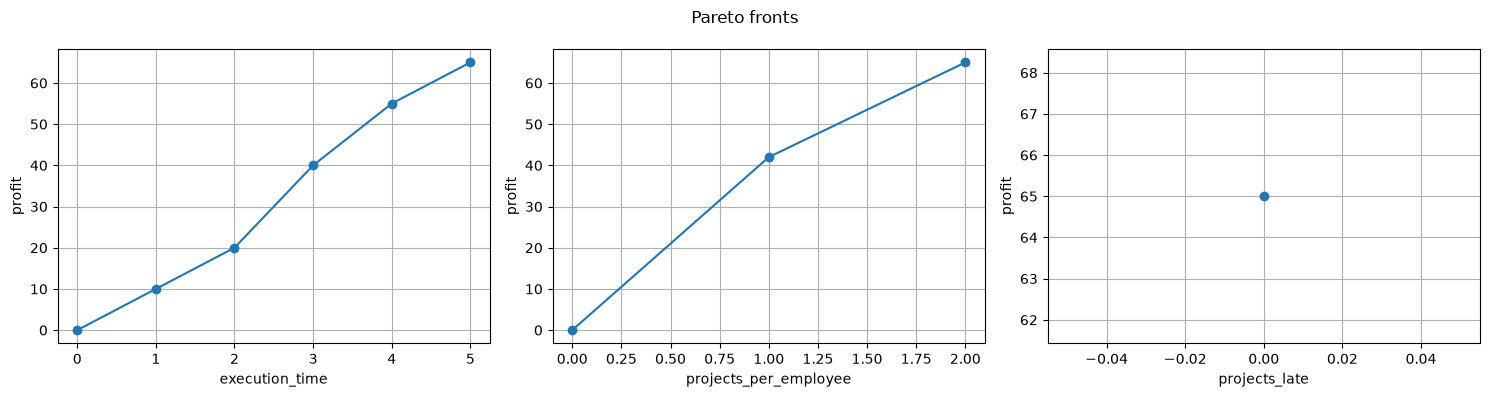

In [31]:
def plot_fronts(fronts, title):
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    for ax, (name, front) in zip(axes, fronts.items()):
        ax.plot([s[name] for s in front], [s["profit"] for s in front], "o-")
        ax.set_xlabel(name)
        ax.set_ylabel("profit")
        ax.grid(True)
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


plot_fronts(fronts, "Pareto fronts")

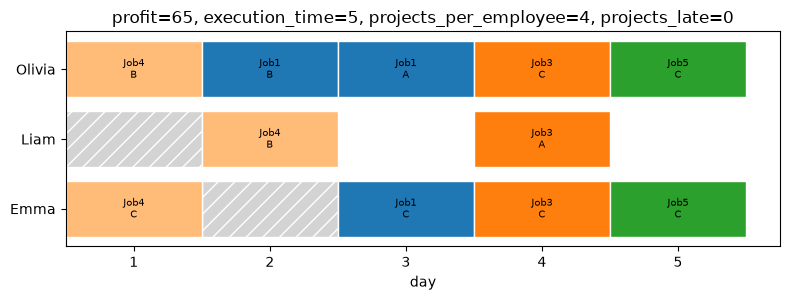

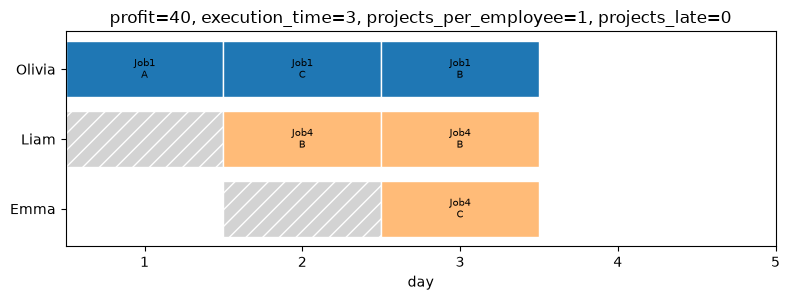

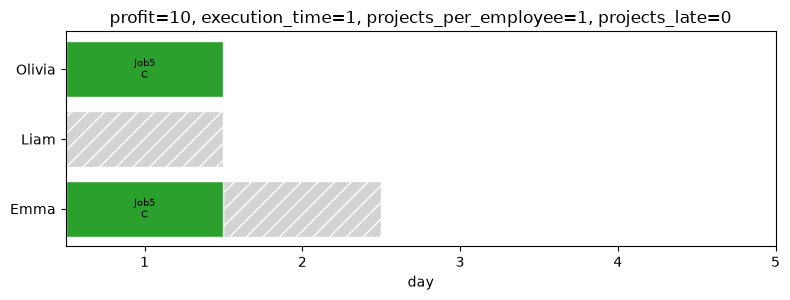

In [32]:
def plot_schedule(solution, S, H, V_i, J, title):
    colors = {j: plt.cm.tab20(number % 20) for number, j in enumerate(J)}
    fig, ax = plt.subplots(figsize=(max(8, len(H) * 0.55), len(S) * 0.7 + 1))

    for row, i in enumerate(S):
        for t in V_i[i]:
            ax.barh(row, 1, left=t - 0.5, color="lightgrey", hatch="//", edgecolor="white")
    for (i, t, j, k) in solution["schedule"]:
        ax.barh(S.index(i), 1, left=t - 0.5, color=colors[j], edgecolor="white")
        ax.text(t, S.index(i), f"{j}\n{k}", ha="center", va="center", fontsize=7)

    ax.set_yticks(range(len(S)))
    ax.set_yticklabels(S)
    ax.invert_yaxis()
    ax.set_xticks(list(H))
    ax.set_xlabel("day")
    ax.set_title(title)
    plt.tight_layout()
    plt.show()


# best profit, middle point and shortest schedule that still makes a profit
front = [s for s in fronts["execution_time"] if s["profit"] > 0]
for s in [front[0], front[len(front) // 2], front[-1]]:
    title = (f"profit={s['profit']}, execution_time={s['execution_time']}, "
             f"projects_per_employee={s['projects_per_employee']}, projects_late={s['projects_late']}")
    plot_schedule(s, S, H, V_i, J, title)

In [33]:
def dominates(a, b, names):
    at_least_as_good = a["profit"] >= b["profit"] and all(a[n] <= b[n] for n in names)
    strictly_better = a["profit"] > b["profit"] or any(a[n] < b[n] for n in names)
    return at_least_as_good and strictly_better


def keep_non_dominated(solutions, names):
    front = []
    seen = set()
    for s in solutions:
        point = (s["profit"],) + tuple(s[n] for n in names)
        if point in seen:
            continue
        if not any(dominates(other, s, names) for other in solutions):
            front.append(s)
            seen.add(point)
    return front


def pareto_front_3d(m, x, objectives, name_1, name_2, start_1, start_2, d, g, c):
    solutions = []
    for limit_2 in range(start_2, -1, -1):
        limit_1 = start_1
        while limit_1 >= 0:
            solution = solve_with_limits(m, x, objectives, {name_1: limit_1, name_2: limit_2}, d, g, c)
            if solution is None:
                break
            solutions.append(solution)
            limit_1 = solution[name_1] - 1
    return keep_non_dominated(solutions, [name_1, name_2])

In [34]:
# too slow on the large instance
start = time.time()
max_projects = fronts["projects_per_employee"][0]["projects_per_employee"]
front_3d = pareto_front_3d(m, x, objectives, "execution_time", "projects_per_employee", h, max_projects, d, g, c)
print(len(front_3d), "points in", round(time.time() - start), "s")

pd.DataFrame(front_3d)[["profit", "execution_time", "projects_per_employee"]].sort_values("profit", ascending=False)

7 points in 0 s


,profit,execution_time,projects_per_employee
0,65,5,2
1,55,4,2
6,42,4,1
2,40,3,1
3,20,2,1
4,10,1,1
5,0,0,0


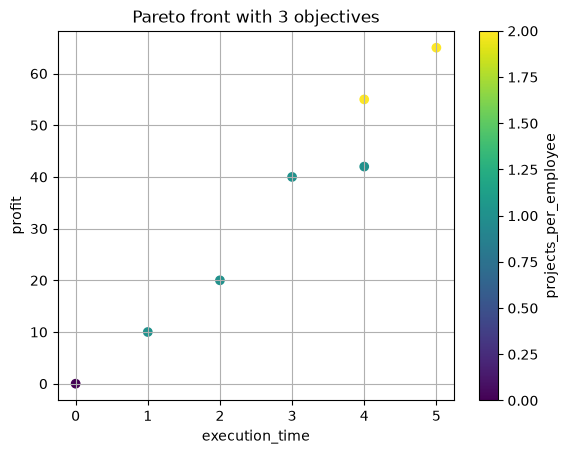

In [35]:
plt.scatter([s["execution_time"] for s in front_3d], [s["profit"] for s in front_3d],
            c=[s["projects_per_employee"] for s in front_3d], cmap="viridis")
plt.colorbar(label="projects_per_employee")
plt.xlabel("execution_time")
plt.ylabel("profit")
plt.title("Pareto front with 3 objectives")
plt.grid(True)
plt.show()

In [36]:
# same model as above, in one function to run it on other instances
def build_model(inst):
    h = inst["horizon"]
    H = range(1, h + 1)
    Q = inst["qualifications"]
    S = [s["name"] for s in inst["staff"]]
    J = [j["name"] for j in inst["jobs"]]
    Q_i = {s["name"]: set(s["qualifications"]) for s in inst["staff"]}
    V_i = {s["name"]: set(s["vacations"]) for s in inst["staff"]}
    Q_j = {j["name"]: set(j["working_days_per_qualification"]) for j in inst["jobs"]}
    n = {(j["name"], k): days for j in inst["jobs"] for k, days in j["working_days_per_qualification"].items()}
    g = {j["name"]: j["gain"] for j in inst["jobs"]}
    d = {j["name"]: j["due_date"] for j in inst["jobs"]}
    c = {j["name"]: j["daily_penalty"] for j in inst["jobs"]}

    m = gp.Model("staff")
    m.Params.OutputFlag = 0
    m.Params.TimeLimit = 60

    idx = [(i, t, j, k) for i in S for t in H if t not in V_i[i] for j in J for k in Q_j[j] & Q_i[i]]
    x = m.addVars(idx, vtype=GRB.BINARY, name="x")
    y = m.addVars(J, vtype=GRB.BINARY, name="y")
    e = m.addVars(J, vtype=GRB.INTEGER, lb=0, ub=h, name="e")
    l = m.addVars(J, vtype=GRB.INTEGER, lb=0, name="l")
    last_day = m.addVar(vtype=GRB.INTEGER, lb=0, ub=h, name="last_day")
    z = m.addVars(S, J, vtype=GRB.BINARY, name="project_worked")
    P = m.addVar(vtype=GRB.INTEGER, lb=0, ub=len(J), name="max_projects")
    r = m.addVars(J, vtype=GRB.BINARY, name="late")

    m.addConstrs((x.sum(i, t, "*", "*") <= 1 for i in S for t in H if t not in V_i[i]))
    m.addConstrs((x.sum("*", "*", j, k) == n[j, k] * y[j] for j in J for k in Q_j[j]))
    m.addConstrs((e[j] >= t * x[i, t, j, k] for (i, t, j, k) in idx))
    m.addConstrs((l[j] >= e[j] - d[j] for j in J))
    m.addConstr(last_day == gp.max_(list(e.values())))
    for i in S:
        for j in J:
            m.addGenConstrOr(z[i, j], [x[i, t, j, k] for t in H for k in Q if (i, t, j, k) in x])
    m.addConstrs((P >= z.sum(i, "*") for i in S))
    m.addConstrs(((r[j] == 0) >> (l[j] == 0) for j in J))
    m.addConstrs(((r[j] == 1) >> (l[j] >= 1) for j in J))

    objectives = {
        "profit": gp.quicksum(g[j] * y[j] - c[j] * l[j] for j in J),
        "execution_time": last_day,
        "projects_per_employee": P,
        "projects_late": r.sum(),
    }
    return m, x, objectives, h, J, d, g, c

In [37]:
# about 5 minutes, mostly the large instance
results = []
all_fronts = {}

for name in ["toy", "medium", "large"]:
    with open(f"data/{name}_instance.json") as f:
        inst_i = json.load(f)
    m_i, x_i, objectives_i, h_i, J_i, d_i, g_i, c_i = build_model(inst_i)
    starts = {"execution_time": h_i, "projects_per_employee": len(J_i), "projects_late": len(J_i)}

    all_fronts[name] = {}
    for objective, start_value in starts.items():
        start = time.time()
        all_fronts[name][objective] = pareto_front(m_i, x_i, objectives_i, objective, start_value, d_i, g_i, c_i)
        results.append({
            "instance": name,
            "x_variables": len(x_i),
            "second_objective": objective,
            "points": len(all_fronts[name][objective]),
            "max_profit": all_fronts[name][objective][0]["profit"],
            "time_s": round(time.time() - start, 1),
        })

pd.DataFrame(results)

,instance,x_variables,second_objective,points,max_profit,time_s
0,toy,90,execution_time,6,65,0.0
1,toy,90,projects_per_employee,3,65,0.0
2,toy,90,projects_late,1,65,0.0
3,medium,1298,execution_time,21,413,3.8
4,medium,1298,projects_per_employee,6,413,14.0
5,medium,1298,projects_late,4,413,3.0
6,large,3939,execution_time,35,817,38.0
7,large,3939,projects_per_employee,8,817,283.1
8,large,3939,projects_late,3,817,8.5


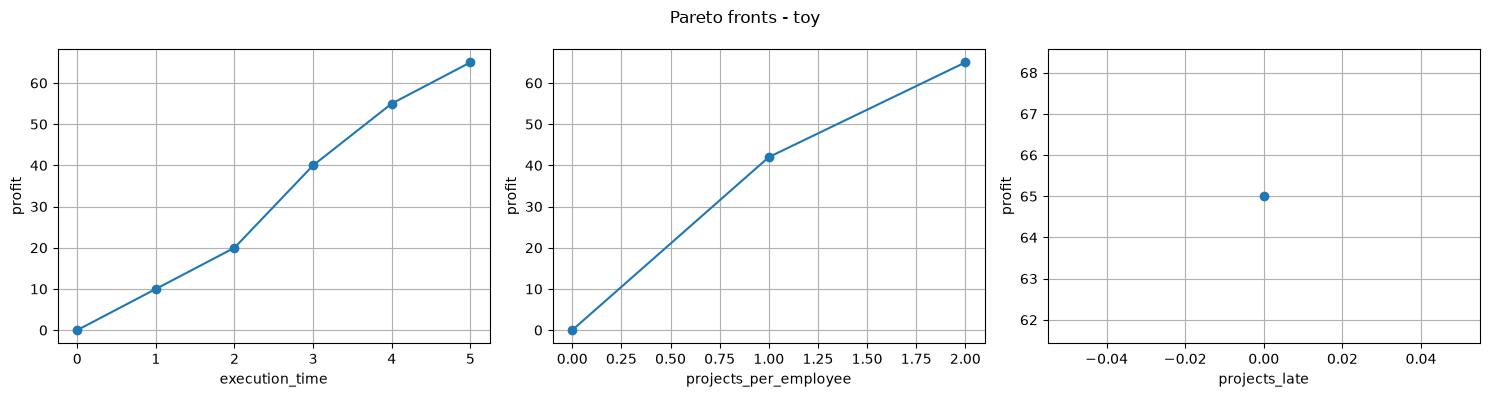

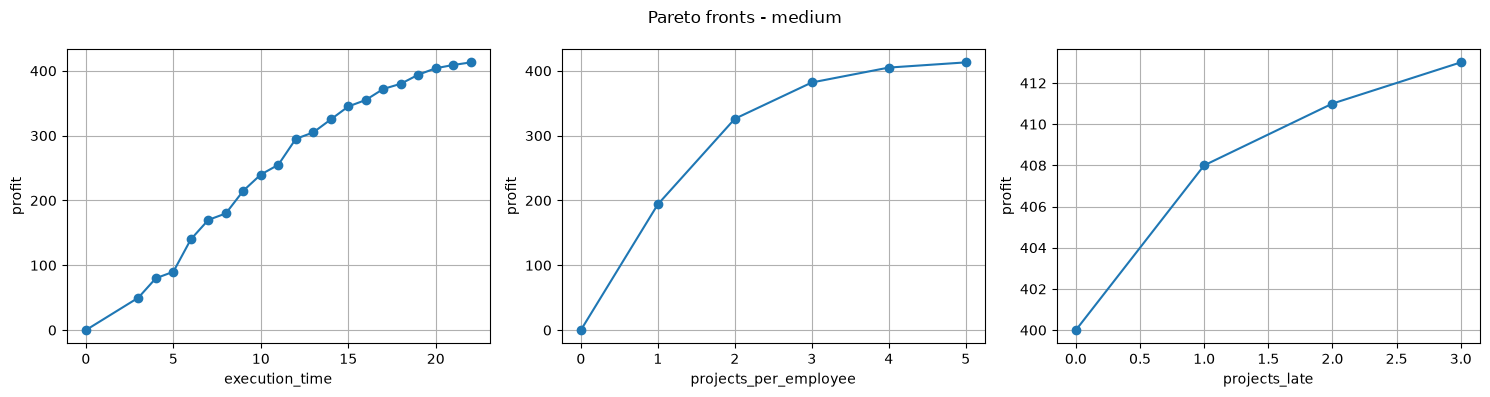

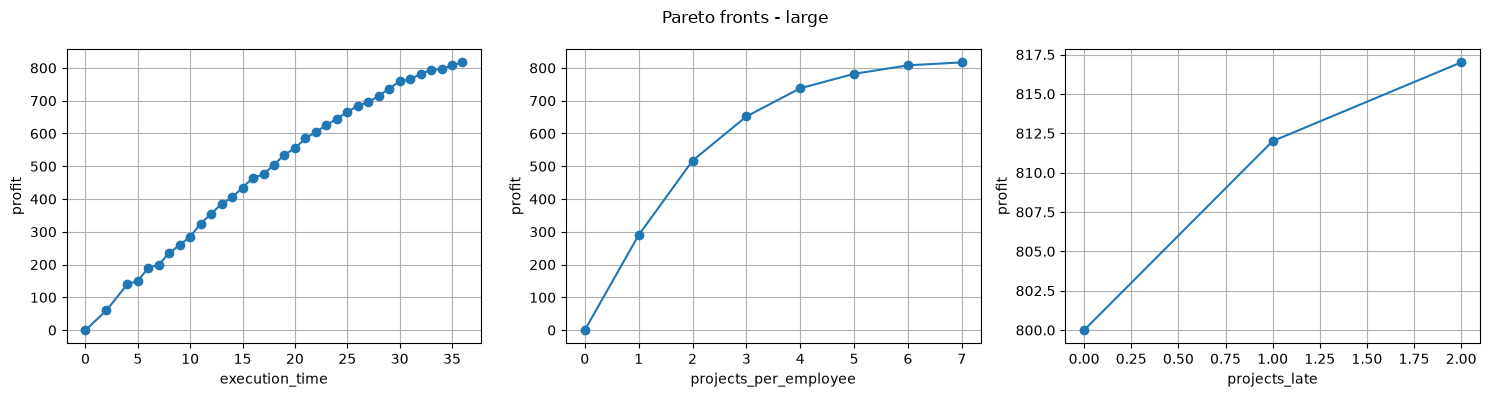

In [38]:
for name in all_fronts:
    plot_fronts(all_fronts[name], f"Pareto fronts - {name}")

In [39]:
def generate_instance(n_staff, n_jobs, horizon, n_qualifications=10, seed=0):
    rng = random.Random(seed)
    qualifications = [chr(ord("A") + q) for q in range(n_qualifications)]

    staff = []
    for s in range(n_staff):
        first_day_off = rng.randint(1, horizon)
        vacations = [t for t in range(first_day_off, first_day_off + rng.randint(0, 5)) if t <= horizon]
        staff.append({
            "name": f"Staff{s + 1}",
            "qualifications": rng.sample(qualifications, rng.randint(2, 5)),
            "vacations": vacations,
        })

    jobs = []
    for j in range(n_jobs):
        required = rng.sample(qualifications, rng.randint(1, 3))
        jobs.append({
            "name": f"Job{j + 1}",
            "gain": rng.choice([10, 15, 20, 25, 30, 40, 50, 60, 70, 80]),
            "due_date": rng.randint(horizon // 3, horizon),
            "daily_penalty": 3,
            "working_days_per_qualification": {k: rng.randint(1, 8) for k in required},
        })

    return {"horizon": horizon, "qualifications": qualifications, "staff": staff, "jobs": jobs}

In [40]:
os.makedirs("data/generated", exist_ok=True)
sizes = [(3, 8, 10), (5, 15, 20), (7, 25, 30), (9, 35, 40), (11, 45, 50)]

benchmark = []
for n_staff, n_jobs, horizon in sizes:
    inst_gen = generate_instance(n_staff, n_jobs, horizon, seed=1)
    with open(f"data/generated/instance_{n_staff}_{n_jobs}_{horizon}.json", "w") as f:
        json.dump(inst_gen, f, indent=4)

    start = time.time()
    m_gen, x_gen, objectives_gen, h_gen, J_gen, d_gen, g_gen, c_gen = build_model(inst_gen)
    front_gen = pareto_front(m_gen, x_gen, objectives_gen, "execution_time", h_gen, d_gen, g_gen, c_gen)
    benchmark.append({
        "staff": n_staff,
        "projects": n_jobs,
        "days": horizon,
        "x_variables": len(x_gen),
        "points": len(front_gen),
        "max_profit": front_gen[0]["profit"],
        "time_s": round(time.time() - start, 1),
    })

benchmark = pd.DataFrame(benchmark)
benchmark

,staff,projects,days,x_variables,points,max_profit,time_s
0,3,8,10,122,2,47,0.0
1,5,15,20,880,15,300,0.3
2,7,25,30,3404,29,998,11.2
3,9,35,40,6960,24,860,4.3
4,11,45,50,14886,37,1935,40.0


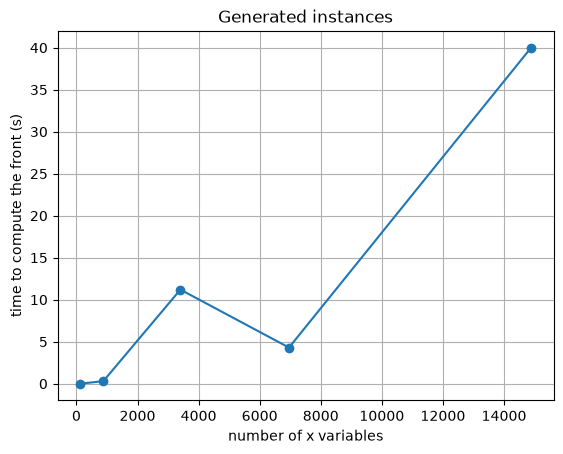

In [41]:
plt.plot(benchmark["x_variables"], benchmark["time_s"], "o-")
plt.xlabel("number of x variables")
plt.ylabel("time to compute the front (s)")
plt.title("Generated instances")
plt.grid(True)
plt.show()